In [4]:
import numpy as np
import pandas as pd

# 1. Load data files
samples_df = pd.read_csv("columns-samples.csv")
donor_df = pd.read_csv("DonorInformation-2.csv")

# 2. DEFINE AND APPLY PRIMARY GROUP (This fixes the missing column issue)
def set_primary_group(row):
    nia = row.get("nia_reagan")
    dementia = row.get("act_demented")
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    return None

donor_df["primary_group"] = donor_df.apply(set_primary_group, axis=1)

# 3. Subset for Hippocampus (HIP) samples
hip_samples = samples_df[samples_df["structure_acronym"] == "HIP"].copy()

print("=== HIPPOCAMPAL RNA-SEQ SAMPLE DATASET ===")
print(f"Total Hippocampal Samples (N): {len(hip_samples)}")
print(f"Unique Donors in HIP: {hip_samples['donor_id'].nunique()}")

# 4. Merge with donor metadata safely
hip_merged = hip_samples.merge(donor_df, on="donor_id", how="left")

# Now 'primary_group' is guaranteed to exist
group_col = "primary_group"
target_groups = ["Resilience-like", "Pathology-positive dementia"]

hip_target = hip_merged[hip_merged[group_col].isin(target_groups)].copy()

counts = hip_target[group_col].value_counts()
pathology_count = counts.get("Pathology-positive dementia", 0)
resilience_count = counts.get("Resilience-like", 0)
group_missingness = hip_target[group_col].isna().sum()

print("\n=== SAMPLE COUNTS BY GROUP ===")
print(counts)

# 3. (Continued) Missingness Summary & Sample Filtering
print("\n=== MISSINGNESS SUMMARY ===")
print(
    hip_target[
        [group_col] + [c for c in ["rin"] if c in hip_target.columns]
    ]
    .isna()
    .sum()
)

# 4. Prepare FPKM expression matrix for HIP samples
fpkm_df = pd.read_csv("fpkm_table_unnormalized.csv")
fpkm_df = fpkm_df.rename(columns={fpkm_df.columns[0]: "gene_id"})

hip_profile_ids = hip_samples["rnaseq_profile_id"].astype(str).tolist()
valid_cols = ["gene_id"] + [
    c for c in fpkm_df.columns if str(c) in hip_profile_ids
]

hip_fpkm = fpkm_df[valid_cols].copy()
print(
    f"\nHippocampal Expression Matrix Dimensions: {hip_fpkm.shape[0]} Genes x {hip_fpkm.shape[1] - 1} Samples"
)

# 5. Build and export summary results directly to a CSV file
summary_results = [
    {
        "Metric": "Total Hippocampal Samples (N)",
        "Category": "Sample Overview",
        "Value": len(hip_samples),
    },
    {
        "Metric": "Unique Donors in HIP",
        "Category": "Sample Overview",
        "Value": hip_samples["donor_id"].nunique(),
    },
    {
        "Metric": "Pathology-positive dementia Count",
        "Category": "Group Breakdown",
        "Value": pathology_count,
    },
    {
        "Metric": "Resilience-like Count",
        "Category": "Group Breakdown",
        "Value": resilience_count,
    },
    {
        "Metric": "Primary Group Missingness",
        "Category": "Quality Control",
        "Value": group_missingness,
    },
    {
        "Metric": "Total Genes Measured",
        "Category": "Expression Matrix",
        "Value": hip_fpkm.shape[0],
    },
    {
        "Metric": "Total Expression Samples",
        "Category": "Expression Matrix",
        "Value": hip_fpkm.shape[1] - 1,
    },
]

summary_df = pd.DataFrame(summary_results)
summary_df.to_csv("hippocampal_qc_summary.csv", index=False)

print("\nSuccessfully saved output summary to 'hippocampal_qc_summary.csv'.")

=== HIPPOCAMPAL RNA-SEQ SAMPLE DATASET ===
Total Hippocampal Samples (N): 94
Unique Donors in HIP: 94

=== SAMPLE COUNTS BY GROUP ===
Pathology-positive dementia    29
Resilience-like                19
Name: primary_group, dtype: int64

=== MISSINGNESS SUMMARY ===
primary_group    0
dtype: int64

Hippocampal Expression Matrix Dimensions: 50281 Genes x 94 Samples

Successfully saved output summary to 'hippocampal_qc_summary.csv'.


In [6]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

# ---------------------------------------------------------
# 1. Load the merged regional dataset
# ---------------------------------------------------------

df = pd.read_csv("Regional_Protein_Pathology_With_Donor_Metadata.csv")

# ---------------------------------------------------------
# 2. Select hippocampus
# ---------------------------------------------------------

hip_df = df[df["structure_acronym"] == "HIP"].copy()

# ---------------------------------------------------------
# 3. Keep only the two pathology-positive groups
# ---------------------------------------------------------

path_df = hip_df[
    hip_df["primary_group"].isin(
        ["Resilience-like", "Pathology-positive dementia"]
    )
].copy()

# ---------------------------------------------------------
# 4. Create binary clinical outcome
#    0 = resilience-like
#    1 = pathology-positive dementia
# ---------------------------------------------------------

path_df["dementia_status"] = (
    path_df["primary_group"] == "Pathology-positive dementia"
).astype(int)

# ---------------------------------------------------------
# 5. Keep complete cases
# ---------------------------------------------------------

path_df = path_df.dropna(
    subset=["ihc_at8", "braak", "cerad", "dementia_status"]
).copy()

print("Number of donors:", len(path_df))
print(path_df["dementia_status"].value_counts())

# ---------------------------------------------------------
# 6. Standardize AT8
#    This makes the odds ratio interpretable per 1-SD
#    increase in AT8.
# ---------------------------------------------------------

path_df["AT8_z"] = (
    path_df["ihc_at8"] - path_df["ihc_at8"].mean()
) / path_df["ihc_at8"].std()

# ---------------------------------------------------------
# 7. Fit sequential logistic regression models
# ---------------------------------------------------------

model0 = smf.logit(
    "dementia_status ~ AT8_z",
    data=path_df
).fit()

model1 = smf.logit(
    "dementia_status ~ AT8_z + braak",
    data=path_df
).fit()

model2 = smf.logit(
    "dementia_status ~ AT8_z + cerad",
    data=path_df
).fit()

model3 = smf.logit(
    "dementia_status ~ AT8_z + braak + cerad",
    data=path_df
).fit()

# ---------------------------------------------------------
# 8. Function to report odds ratios and 95% CIs
# ---------------------------------------------------------

def odds_ratio_table(model):
    params = model.params
    conf = model.conf_int()

    results = pd.DataFrame({
        "Beta": params,
        "Odds_Ratio": np.exp(params),
        "CI_Lower": np.exp(conf[0]),
        "CI_Upper": np.exp(conf[1]),
        "p_value": model.pvalues
    })

    return results

print("\nMODEL 0: AT8 only")
print(odds_ratio_table(model0))

print("\nMODEL 1: AT8 + Braak")
print(odds_ratio_table(model1))

print("\nMODEL 2: AT8 + CERAD")
print(odds_ratio_table(model2))

print("\nMODEL 3: AT8 + Braak + CERAD")
print(odds_ratio_table(model3))

Number of donors: 48
1    29
0    19
Name: dementia_status, dtype: int64
Optimization terminated successfully.
         Current function value: 0.525044
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.459737
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.471290
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.412048
         Iterations 7

MODEL 0: AT8 only
               Beta  Odds_Ratio  CI_Lower  CI_Upper   p_value
Intercept  0.589343    1.802803  0.896053  3.627127  0.098482
AT8_z      1.359866    3.895672  1.673088  9.070807  0.001613

MODEL 1: AT8 + Braak
               Beta  Odds_Ratio  CI_Lower  CI_Upper   p_value
Intercept -3.134007    0.043543  0.001611  1.176568  0.062421
AT8_z      1.038611    2.825291  1.085059  7.356528  0.033407
braak      0.811205    2.250618  1.117672  4.531994  0.023119

MODEL 2: AT8 + CERAD
               Beta  O

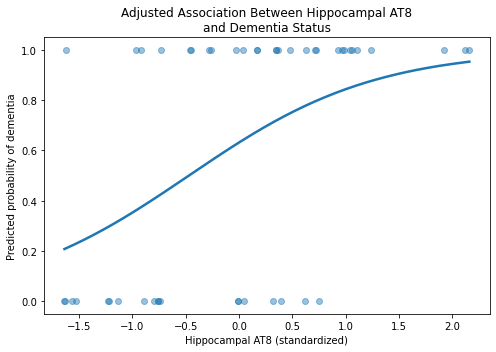

Plot successfully saved to 'at8_dementia_association_plot.pdf'


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create a range of standardized AT8 values
at8_grid = np.linspace(
    path_df["AT8_z"].min(),
    path_df["AT8_z"].max(),
    200
)

# Hold Braak and CERAD at their median values
braak_ref = path_df["braak"].median()
cerad_ref = path_df["cerad"].median()

prediction_df = pd.DataFrame({
    "AT8_z": at8_grid,
    "braak": braak_ref,
    "cerad": cerad_ref
})

# Predicted probability of dementia from the adjusted model
prediction_df["predicted_probability"] = model3.predict(prediction_df)

# Plot
plt.figure(figsize=(7, 5))

plt.plot(
    prediction_df["AT8_z"],
    prediction_df["predicted_probability"],
    linewidth=2.5
)

# Show observed donors at 0 and 1 for context
plt.scatter(
    path_df["AT8_z"],
    path_df["dementia_status"],
    alpha=0.45
)

plt.xlabel("Hippocampal AT8 (standardized)")
plt.ylabel("Predicted probability of dementia")
plt.title(
    "Adjusted Association Between Hippocampal AT8\n"
    "and Dementia Status"
)

plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

plt.savefig(
    "at8_dementia_association_plot.pdf", format="pdf", bbox_inches="tight"
)

# Close plot figure to free memory
plt.close()

print("Plot successfully saved to 'at8_dementia_association_plot.pdf'")